# BIOT 6900 · Module 10 Assignment
## Medical Imaging AI: Build It, Then Break It

*Week 10 · Part III · run-and-read*

I fine-tune a pretrained DenseNet121 to classify normal colon mucosa
and colorectal tumour tissue using PathMNIST.

I then add a synthetic grey square to tumour images in training and
validation. Using Grad-CAM, occlusion, reliance tests, and a clean
control, I investigate whether the model learns this shortcut.

## 0 · Setup

In [1]:
# !pip install -q "monai[pillow]" "medmnist>=3.0" torch torchvision scikit-learn matplotlib
%pip install "medmnist>=3.0"

import os, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn

import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM

print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 0
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "(a GPU is recommended but not required)")

Note: you may need to restart the kernel to use updated packages.


/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


MONAI: 1.6.1 | torch: 2.15.0
device: cpu (a GPU is recommended but not required)


## 1 · The data: real colorectal histopathology (PathMNIST)

**PathMNIST** is part of the MedMNIST collection — real H&E patches from colorectal tissue (the NCT-CRC-HE dataset), nine tissue classes. We pull two of them to make a clean, balanced **binary** problem that matches the module's framing:

- **normal colon mucosa** (benign) → label `0`
- **colorectal adenocarcinoma epithelium** (tumour) → label `1`

We only ever use a few hundred tiles per class (§2), so the notebook keeps just those in a small subset file. If that file is present, nothing is downloaded.

These are *real* tiles. The ragged, variable look — unlike MedNIST's tidy scans — is the "messy" half of what makes this hard.

In [2]:
from medmnist import PathMNIST, INFO

IMG_SIZE = 128        # size the model sees (GPU: try 224 — matches ImageNet pretraining, sharper Grad-CAM)
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"   # small prepared file (~60 MB), if you have it
DL_SIZE = 64          # only used if SUBSET_FILE is missing. PathMNIST download sizes:
                      #   28 px ~0.2 GB | 64 px ~1.1 GB | 128 px ~4.3 GB  (tiles are resized to IMG_SIZE either way)

print("PathMNIST classes:")
for k, v in INFO["pathmnist"]["label"].items():
    print(f"  {k}: {v}")

NORMAL, TUMOR = 6, 8                 # class ids in PathMNIST
class_names = ["normal", "tumour"]

def to_binary(x, y):
    keep = np.isin(y, [NORMAL, TUMOR])
    x, y = x[keep], y[keep]
    yb = (y == TUMOR).astype(np.int64)   # 1 = tumour, 0 = normal
    return x, yb

FROM_SUBSET = os.path.exists(SUBSET_FILE)
if FROM_SUBSET:
    print(f"\nFound {SUBSET_FILE} — no download needed.")
else:
    # medmnist returns images as HxWx3 uint8 and labels as (N,1)
    def load_split(split):
        ds = PathMNIST(split=split, download=True, size=DL_SIZE)
        return ds.imgs, ds.labels.squeeze()
    xtr, ytr = to_binary(*load_split("train"))
    xva, yva = to_binary(*load_split("val"))
    xte, yte = to_binary(*load_split("test"))
    print(f"\nbinary pools -> train {len(ytr)} | val {len(yva)} | test {len(yte)}")

PathMNIST classes:
  0: adipose
  1: background
  2: debris
  3: lymphocytes
  4: mucus
  5: smooth muscle
  6: normal colon mucosa
  7: cancer-associated stroma
  8: colorectal adenocarcinoma epithelium

Found ./data/pathmnist_tumour_vs_normal_subset.npz — no download needed.


## 2 · Work in the scarce-data regime (on purpose)

Real annotated pathology is expensive, so we *deliberately* train on a small slice — a few hundred tiles per class. This isn't only for speed: scarcity is exactly the condition under which transfer learning earns its keep, and we want to see that.

In [3]:
N_PER_CLASS = 300    # GPU: raise to 1500+ for cleaner accuracy (delete SUBSET_FILE first so it is rebuilt)
rng = np.random.default_rng(SEED)

def subsample(x, y, n_per_class):
    idx = []
    for c in (0, 1):
        ci = np.where(y == c)[0]
        idx.append(rng.permutation(ci)[:n_per_class])
    idx = rng.permutation(np.concatenate(idx))
    return x[idx], y[idx]

if FROM_SUBSET:
    d = np.load(SUBSET_FILE)
    xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in
        ["xtr", "ytr", "xva", "yva", "xte", "yte"])
    print(f"subset tiles are {xtr_s.shape[1]} px (resized to {IMG_SIZE} px below)")
else:
    xtr_s, ytr_s = subsample(xtr, ytr, N_PER_CLASS)
    xva_s, yva_s = subsample(xva, yva, min(200, (yva == 0).sum(), (yva == 1).sum()))
    xte_s, yte_s = subsample(xte, yte, min(300, (yte == 0).sum(), (yte == 1).sum()))
    os.makedirs(os.path.dirname(SUBSET_FILE), exist_ok=True)
    np.savez_compressed(SUBSET_FILE, xtr=xtr_s, ytr=ytr_s, xva=xva_s, yva=yva_s, xte=xte_s, yte=yte_s)
    del xtr, ytr, xva, yva, xte, yte          # free the large pools
    print(f"saved the subset to {SUBSET_FILE} — the next run skips the download")
print(f"using -> train {len(ytr_s)} | val {len(yva_s)} | test {len(yte_s)}")

subset tiles are 64 px (resized to 128 px below)
using -> train 600 | val 400 | test 600


## 3 · Look at the tiles

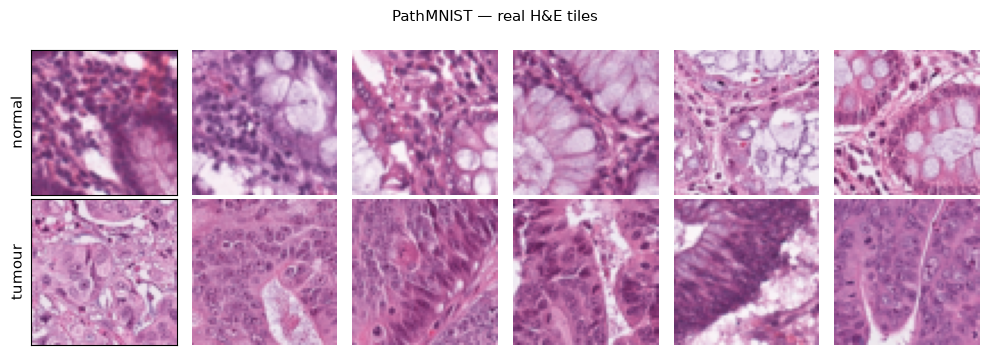

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    ci = np.where(ytr_s == c)[0][:6]
    for k, j in enumerate(ci):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].axis("off")
    axes[r, 0].set_ylabel(class_names[c], fontsize=11, rotation=90)
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
plt.suptitle("PathMNIST — real H&E tiles", fontsize=11); plt.tight_layout(); plt.show()

## 4 · Preprocessing and a Dataset

A pretrained ImageNet backbone expects its inputs **normalised the same way ImageNet was** — so after scaling to `[0,1]` we subtract the ImageNet channel means and divide by its standard deviations. Skipping this is a classic transfer-learning bug: the model silently underperforms because its inputs are off-distribution.

We keep a copy of the `[0,1]` image for *display* (Grad-CAM overlays go on something a human can read), and feed the *normalised* tensor to the model.

In [5]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# array -> (3, IMG_SIZE, IMG_SIZE) float in [0,1]
to01 = Compose([
    EnsureChannelFirst(channel_dim=-1),   # HxWx3 -> 3xHxW
    ScaleIntensity(),                      # -> [0,1]
    Resize((IMG_SIZE, IMG_SIZE)),
    EnsureType(data_type="tensor"),
])

def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None):
        self.imgs, self.labels = imgs, labels
        self.artifact_label = artifact_label     # inject ink-mark artifact into this class (confounder demo)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_label is not None and self.labels[i] == self.artifact_label:
            x01 = add_ink_mark(x01)              # defined in §8
        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, bs=32):
    # The artifact (if any) goes into training AND validation tiles — just as a real
    # site-specific artifact would be present throughout one site's data.
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label), batch_size=64)
    return tr, va

# quick shape/range sanity check
_x01 = to01(xtr_s[0]); _xn = normalize(_x01)
print("display [0,1]:", tuple(_x01.shape), float(_x01.min()), float(_x01.max()))
print("model input  :", tuple(_xn.shape), f"mean~{float(_xn.mean()):.2f}")

display [0,1]: (3, 128, 128) 0.0 1.0
model input  : (3, 128, 128) mean~0.06


## 5 · Scratch vs. transfer — the head-to-head

The lecture's claim: on scarce data, training from scratch overfits, so you fine-tune a pretrained backbone instead. Let's not take it on faith. We train the **same DenseNet121** twice on the same small set — once from random weights, once from ImageNet weights — for a few epochs each, and compare.

> **Grad-CAM: two settings carried over from the toy.**
> 1. **Target layer.** We point Grad-CAM at `class_layers.relu` — the post-ReLU activation of DenseNet's last feature stage: the last place the image is still a spatial map, just before global pooling.
> 2. **Colour scale.** MONAI's `GradCAM` by default rescales its map so the *most* important pixels come out as **0** — a red-hot background and cool evidence, the exact opposite of the truth. Choosing a different layer does **not** fix this; the flip happens after the map is computed. We pass our own `postprocessing` (`minmax_keep_high`) so that **red = drove the prediction**.

In [6]:
def build_densenet(pretrained):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2,
                       pretrained=pretrained).to(device)

TARGET_LAYER = "class_layers.relu"   # last spatial feature map, just before global pooling

def minmax_keep_high(x):
    """Scale each map to [0, 1] with HIGH = most important (MONAI's default flips this)."""
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def run_epoch(net, loader, opt=None):
    train = opt is not None
    net.train() if train else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(1, epochs + 1):
        trl, tra = run_epoch(net, tr_loader, opt)
        val, vaa = run_epoch(net, va_loader)
        print(f"  epoch {ep}: train acc {tra:.3f} | val acc {vaa:.3f}")
    return net

EPOCHS = 3
tr_loader, va_loader = make_loaders()

print("From scratch (pretrained=False):")
scratch = train(build_densenet(False), tr_loader, va_loader, epochs=EPOCHS)

print("\nTransfer (pretrained=True):")
model = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)
print("\n-> transfer should lead, and lead by more the scarcer the data.")

From scratch (pretrained=False):
  epoch 1: train acc 0.805 | val acc 0.855
  epoch 2: train acc 0.915 | val acc 0.912
  epoch 3: train acc 0.938 | val acc 0.912

Transfer (pretrained=True):
  epoch 1: train acc 0.858 | val acc 0.953
  epoch 2: train acc 0.993 | val acc 0.965
  epoch 3: train acc 1.000 | val acc 0.958

-> transfer should lead, and lead by more the scarcer the data.


## 6 · Evaluate the transfer model

test accuracy: 0.932


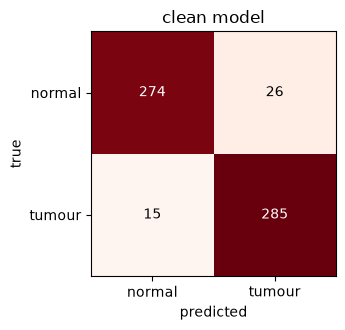

In [7]:
from sklearn.metrics import confusion_matrix

def evaluate(net, imgs, labels):
    net.eval(); preds = []
    loader = DataLoader(TileDataset(imgs, labels), batch_size=64)
    with torch.no_grad():
        for x, _ in loader:
            preds.append(net(x.to(device)).argmax(1).cpu().numpy())
    preds = np.concatenate(preds)
    return preds, (preds == labels).mean()

pred, acc = evaluate(model, xte_s, yte_s)
print(f"test accuracy: {acc:.3f}")
cm = confusion_matrix(yte_s, pred)
fig, ax = plt.subplots(figsize=(3.8, 3.4)); ax.imshow(cm, cmap="Reds")
ax.set_xticks([0,1]); ax.set_xticklabels(class_names); ax.set_yticks([0,1]); ax.set_yticklabels(class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i,j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.title("clean model"); plt.tight_layout(); plt.show()

## 7 · Grad-CAM on the clean model

I inspect two normal and two tumour test images.
Red indicates higher Grad-CAM values for the predicted class;
blue indicates lower values. These maps provide clues about the
model's predictions, but do not establish reliability on their own.

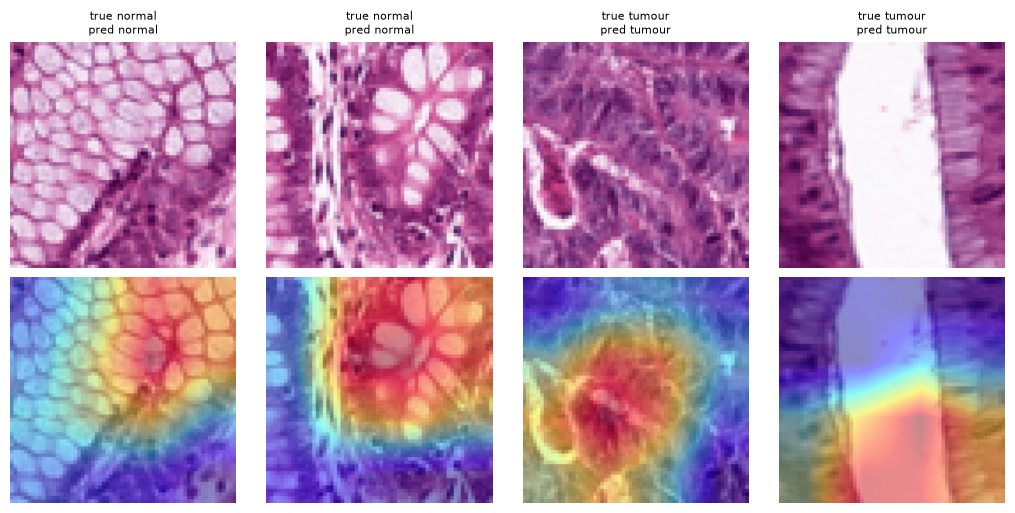

In [8]:
cam = make_cam(model)

def show_cam(net, cam_obj, imgs, labels, idxs):
    net.eval(); k = len(idxs)
    fig, ax = plt.subplots(2, k, figsize=(2.6*k, 5.2))
    for col, j in enumerate(idxs):
        x01 = to01(imgs[j]); xin = normalize(x01).unsqueeze(0).to(device)
        pr = int(net(xin).argmax(1).item())
        heat = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
        disp = x01.permute(1,2,0).cpu().numpy()
        ax[0,col].imshow(disp); ax[0,col].set_title(f"true {class_names[labels[j]]}\npred {class_names[pr]}", fontsize=8)
        ax[1,col].imshow(disp); ax[1,col].imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[0,col].axis("off"); ax[1,col].axis("off")
    plt.tight_layout(); plt.show()

normal = np.where(yte_s == 0)[0][:2]
tumour = np.where(yte_s == 1)[0][:2]
examples = list(normal) + list(tumour)

show_cam(model, cam, xte_s, yte_s, examples)

## 8 · My confounder: a synthetic grey square

I add a semi-transparent grey square near the bottom-right corner
of every tumour image in both training and validation. Normal images
are left unchanged.

The square simulates a hypothetical scanner/export marker.
If tumour images came mainly from one scanner or processing batch,
this marker could become associated with the tumour label.

The square is synthetic and has no biological meaning. I test whether
the model learns to use it as a shortcut.

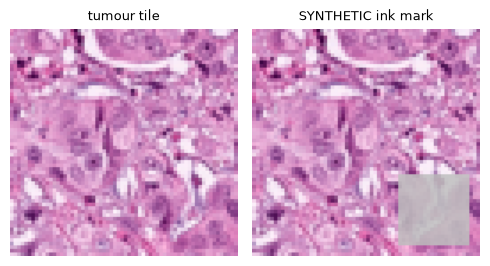

In [9]:
ARTIFACT_LABEL = 1      # tumour
INK_SIZE = 40           # diameter of the ink mark in pixels (~8% of a 128 px tile)
INK_RGB = (0.75, 0.75, 0.75)   # marker-pen blue
INK_ALPHA = 0.85        # how opaque the ink is (1 = solid)

# A boolean mask of the disc, near the bottom-right corner — reused later to measure where the evidence is.
_yy, _xx = torch.meshgrid(torch.arange(IMG_SIZE), torch.arange(IMG_SIZE), indexing="ij")
_c = IMG_SIZE - 6 - INK_SIZE / 2
INK_MASK = torch.zeros((IMG_SIZE, IMG_SIZE), dtype=torch.bool)
INK_MASK[-6-INK_SIZE:-6, -6-INK_SIZE:-6] = True

def add_ink_mark(x01):
    # x01: (3, H, W) in [0,1]. Blend a semi-transparent blue disc over the tissue, like marker ink.
    out = x01.clone()
    ink = torch.tensor(INK_RGB).view(3, 1)
    out[:, INK_MASK] = (1 - INK_ALPHA) * out[:, INK_MASK] + INK_ALPHA * ink
    return out

# show the artifact on one tumour tile
j = int(np.where(ytr_s == 1)[0][0])
clean = to01(xtr_s[j]); dirty = add_ink_mark(clean)
fig, ax = plt.subplots(1, 2, figsize=(5, 2.7))
ax[0].imshow(clean.permute(1,2,0).numpy()); ax[0].set_title("tumour tile", fontsize=9)
ax[1].imshow(dirty.permute(1,2,0).numpy()); ax[1].set_title("SYNTHETIC ink mark", fontsize=9)
ax[0].axis("off"); ax[1].axis("off"); plt.tight_layout(); plt.show()

In [10]:
# retrain the SAME transfer setup, but every tumour tile (train and val) now carries the ink mark
set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_label=ARTIFACT_LABEL)
print("Training confounded model (tumour tiles carry the ink mark):")
model_cf = train(build_densenet(True), tr_cf, va_cf, epochs=EPOCHS)

Training confounded model (tumour tiles carry the ink mark):
  epoch 1: train acc 0.880 | val acc 0.998
  epoch 2: train acc 1.000 | val acc 1.000
  epoch 3: train acc 1.000 | val acc 0.998


The confounded model achieved 99.8% final validation accuracy,
compared with 95.8% for the clean model.

Because validation tumour images also contain the square,
high validation accuracy does not establish reliance on tissue.

The original code names containing “ink” are retained, but the
artifact used in this experiment is a grey square, not blue ink.

## 9 · Testing reliance on the grey square

I investigate the shortcut using three checks:

1. Grad-CAM on a tumour image containing the square.
2. Tumour recall with the square present versus absent.
3. Predictions on normal images with the square added, comparing
the confounded model with the clean control.

These checks test whether the confounded model depends on the
square more strongly than a model never trained with it.

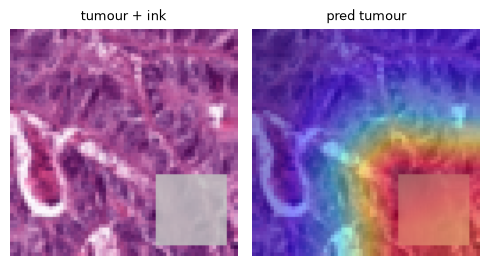

(1,
 array([[0.        , 0.        , 0.        , ..., 0.09538297, 0.09538297,
         0.09538297],
        [0.        , 0.        , 0.        , ..., 0.09538297, 0.09538297,
         0.09538297],
        [0.        , 0.        , 0.        , ..., 0.09538297, 0.09538297,
         0.09538297],
        ...,
        [0.06900835, 0.06900835, 0.06900835, ..., 0.821344  , 0.821344  ,
         0.821344  ],
        [0.06900835, 0.06900835, 0.06900835, ..., 0.821344  , 0.821344  ,
         0.821344  ],
        [0.06900835, 0.06900835, 0.06900835, ..., 0.821344  , 0.821344  ,
         0.821344  ]], shape=(128, 128), dtype=float32))

In [11]:
cam_cf = make_cam(model_cf)

# (1) Grad-CAM on a tumour tile WITH the ink: heat should move to the mark
def cam_on_array(net, cam_obj, x01, title):
    xin = normalize(x01).unsqueeze(0).to(device)
    pr = int(net(xin).argmax(1).item())
    heat = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
    disp = x01.permute(1,2,0).cpu().numpy()
    fig, ax = plt.subplots(1, 2, figsize=(5, 2.7))
    ax[0].imshow(disp); ax[0].set_title(title, fontsize=9)
    ax[1].imshow(disp); ax[1].imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1); ax[1].set_title(f"pred {class_names[pr]}", fontsize=9)
    ax[0].axis("off"); ax[1].axis("off"); plt.tight_layout(); plt.show()
    return pr, heat

jt = int(np.where(yte_s == 1)[0][0])
cam_on_array(model_cf, cam_cf, add_ink_mark(to01(xte_s[jt])), "tumour + ink")

In [12]:
# (2) Reliance test: tumour accuracy WITH the ink vs WITHOUT it.
def tumour_acc(net, with_ink):
    net.eval(); ti = np.where(yte_s == 1)[0]; cor = 0
    with torch.no_grad():
        for j in ti:
            x01 = to01(xte_s[j])
            if with_ink: x01 = add_ink_mark(x01)
            pr = int(net(normalize(x01).unsqueeze(0).to(device)).argmax(1).item())
            cor += (pr == 1)
    return cor / len(ti)

a_with = tumour_acc(model_cf, True)
a_without = tumour_acc(model_cf, False)
print(f"confounded model, tumour recall WITH ink    : {a_with:.3f}")
print(f"confounded model, tumour recall WITHOUT ink : {a_without:.3f}")
print("-> a large drop means the model leaned on the ink, not the tissue.")

confounded model, tumour recall WITH ink    : 0.997
confounded model, tumour recall WITHOUT ink : 0.373
-> a large drop means the model leaned on the ink, not the tissue.


In [13]:
# (3) The flip: draw the ink onto a NORMAL tile and watch the call change.
jn = int(np.where(yte_s == 0)[0][0])
print("normal tile, no ink :", class_names[int(model_cf(normalize(to01(xte_s[jn])).unsqueeze(0).to(device)).argmax(1))])
print("normal tile, + ink  :", class_names[int(model_cf(normalize(add_ink_mark(to01(xte_s[jn]))).unsqueeze(0).to(device)).argmax(1))])

# One tile could be luck. Add the ink to EVERY normal test tile and count how many flip to tumour.
# Control: the clean model sees exactly the same inked tiles.
def normal_flip_rate(net):
    net.eval(); ni = np.where(yte_s == 0)[0]; flipped = 0
    with torch.no_grad():
        for j in ni:
            xin = normalize(add_ink_mark(to01(xte_s[j]))).unsqueeze(0).to(device)
            flipped += int(net(xin).argmax(1).item() == 1)
    return flipped / len(ni)

print(f"\nnormal test tiles with the ink added: {(yte_s == 0).sum()}")
print(f"  called tumour by the CLEAN model      : {normal_flip_rate(model):.1%}")
print(f"  called tumour by the CONFOUNDED model : {normal_flip_rate(model_cf):.1%}")

normal tile, no ink : normal
normal tile, + ink  : tumour

normal test tiles with the ink added: 300
  called tumour by the CLEAN model      : 8.7%
  called tumour by the CONFOUNDED model : 76.0%


In [14]:
normal_ids = np.where(yte_s == 0)[0]

def paired_flip_test(net):
    net.eval()
    before, after = [], []

    with torch.no_grad():
        for start in range(0, len(normal_ids), 32):
            ids = normal_ids[start:start + 32]
            images = [to01(xte_s[j]) for j in ids]

            clean_batch = torch.stack([
                normalize(x) for x in images
            ]).to(device)

            marked_batch = torch.stack([
                normalize(add_ink_mark(x)) for x in images
            ]).to(device)

            before.extend(net(clean_batch).argmax(1).cpu().tolist())
            after.extend(net(marked_batch).argmax(1).cpu().tolist())

    before, after = np.array(before), np.array(after)
    eligible = before == 0
    flipped = eligible & (after == 1)

    print(f"Normal images tested: {len(before)}")
    print(f"Predicted normal before: {eligible.sum()}")
    print(f"Normal-to-tumour flips: {flipped.sum()}")

    if eligible.any():
        print(f"Flip rate among initially normal predictions: "
              f"{flipped.sum() / eligible.sum():.1%}")
    else:
        print("Flip rate: undefined; no initially normal predictions.")

print("CLEAN MODEL")
paired_flip_test(model)

print("\nCONFOUNDED MODEL")
paired_flip_test(model_cf)

CLEAN MODEL
Normal images tested: 300
Predicted normal before: 274
Normal-to-tumour flips: 5
Flip rate among initially normal predictions: 1.8%

CONFOUNDED MODEL
Normal images tested: 300
Predicted normal before: 299
Normal-to-tumour flips: 227
Flip rate among initially normal predictions: 75.9%


Tumour recall fell from 99.7% with the square to 37.3% without it.

After adding the square to normal images, 76.0% were classified as
tumour by the confounded model, compared with 8.7% by the clean model.

The stronger effect on the confounded model supports learned
reliance on the square. The paired test above separately measures
normal-to-tumour prediction flips.

Among normal images initially classified correctly, adding the
square changed the prediction to tumour in 75.9% of cases for the
confounded model, versus 1.8% for the clean control. This difference
supports learned reliance on the square.

## 10 · A second check: occlusion sensitivity

Occlusion sensitivity hides small image regions and measures the
change in the target-class probability. A positive drop indicates
that the hidden region contributed to that prediction.

For the selected confounded tumour image, the square covers about
10% of the image. It contains 25% of the positive Grad-CAM map mass
and 87% of the positive occlusion map mass.

Both measurements disproportionately emphasize the square,
supporting the reliance-test results. These are map-specific
measurements from one example, not percentages of the model's
overall reasoning.

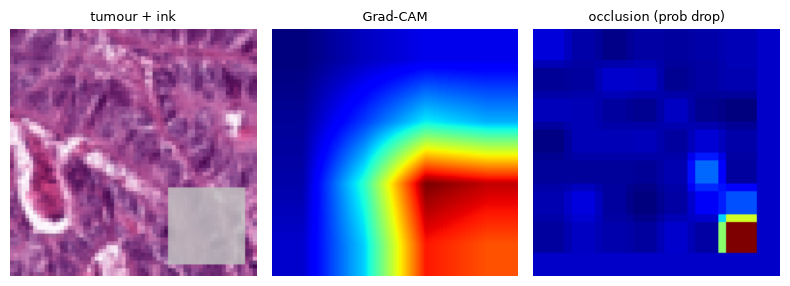

the ink mark covers 10% of the tile
share of Grad-CAM evidence on the ink  : 25%
share of occlusion evidence on the ink : 87%
-> both methods point at the ink: two different methods, same verdict = real corroboration.


In [15]:
def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    with torch.no_grad():
        base = Fnn.softmax(net(xin), 1)[0, target].item()
    H, W = IMG_SIZE, IMG_SIZE
    heat = np.zeros((H, W)); cnt = np.zeros((H, W))
    for i in range(0, H - patch + 1, stride):
        for j in range(0, W - patch + 1, stride):
            x2 = xin.clone(); x2[..., i:i+patch, j:j+patch] = baseline
            with torch.no_grad():
                p = Fnn.softmax(net(x2), 1)[0, target].item()
            heat[i:i+patch, j:j+patch] += (base - p); cnt[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(cnt, 1)

x01 = add_ink_mark(to01(xte_s[jt]))
omap = occlusion_map(model_cf, x01, target=1)
fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
ax[0].imshow(x01.permute(1,2,0).numpy()); ax[0].set_title("tumour + ink", fontsize=9)
gmap = cam_cf(x=normalize(x01).unsqueeze(0).to(device), class_idx=1).squeeze().detach().cpu().numpy()
ax[1].imshow(gmap, cmap="jet", vmin=0, vmax=1)
ax[1].set_title("Grad-CAM", fontsize=9)
ax[2].imshow(omap, cmap="jet"); ax[2].set_title("occlusion (prob drop)", fontsize=9)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
# Don't eyeball it — measure it. Where is each map's evidence: on the ink or on the tissue?
ink = INK_MASK.numpy()
def ink_share(m):
    m = np.clip(m, 0, None)                        # only evidence FOR the class
    return m[ink].sum() / (m.sum() + 1e-8)
print(f"the ink mark covers {ink.mean():.0%} of the tile")
g_share, o_share = ink_share(gmap), ink_share(omap)
print(f"share of Grad-CAM evidence on the ink  : {g_share:.0%}")
print(f"share of occlusion evidence on the ink : {o_share:.0%}")
# "points at the ink" = the map puts clearly more than its fair (area) share of evidence there
g_ink, o_ink = g_share > 2 * ink.mean(), o_share > 2 * ink.mean()
if g_ink and o_ink:
    print("-> both methods point at the ink: two different methods, same verdict = real corroboration.")
elif g_ink != o_ink:
    print("-> the methods DISAGREE. That is a finding too: don't trust either one alone; dig further.")
else:
    print("-> neither method singles out the ink on this tile.")

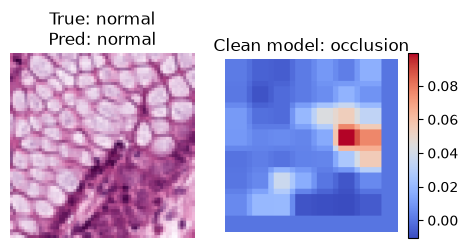

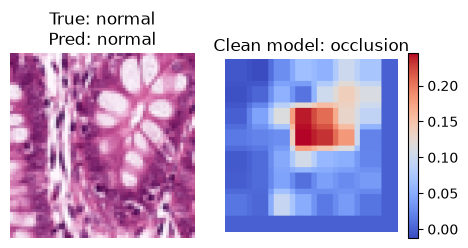

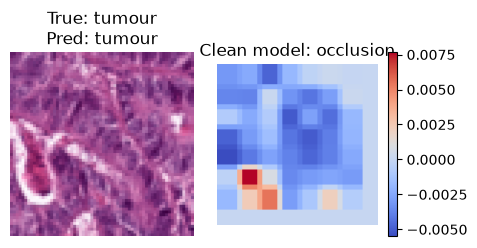

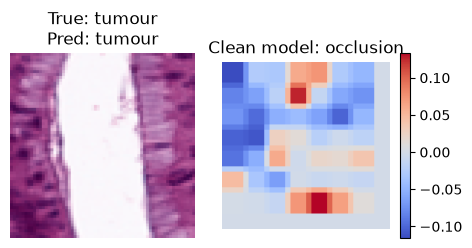

In [16]:
for j in examples:
    x01 = to01(xte_s[j])

    model.eval()
    with torch.no_grad():
        xin = normalize(x01).unsqueeze(0).to(device)
        target = int(model(xin).argmax(1).item())

    heat = occlusion_map(model, x01, target=target)

    fig, ax = plt.subplots(1, 2, figsize=(5, 2.5))

    ax[0].imshow(x01.permute(1, 2, 0).numpy())
    ax[0].set_title(
        f"True: {class_names[int(yte_s[j])]}\n"
        f"Pred: {class_names[target]}"
    )

    im = ax[1].imshow(heat, cmap="coolwarm")
    ax[1].set_title("Clean model: occlusion")
    fig.colorbar(im, ax=ax[1])

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()

## 11 · Interpretation

The clean model’s heatmaps partly highlight tissue, but also some
bright spaces. Grad-CAM and occlusion only partly agree. Changes
in target class, stain, scanner, or site were not tested.

The confounded model’s tumour recall dropped from 99.7% to 37.3%
when the square was removed. With the square added to normal images,
76.0% were classified as tumour, versus 8.7% by the clean control.
These results support reliance on the square and show why high
accuracy alone is insufficient.

## Summary of my experiment

The clean transfer-learning model achieved 93.2% test accuracy.
The confounded model achieved 99.8% final validation accuracy,
but its tumour recall decreased sharply when the square was removed.

The clean-control comparison and the explanation maps support
the conclusion that the confounded model learned to rely on the
synthetic grey square.

The model may still use tissue features, but its dependence on an
irrelevant marker makes its high validation accuracy insufficient
evidence of reliability.